In [73]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers
import numpy as np
from sklearn.cluster import KMeans
import os
from functools import lru_cache
import cv2

In [74]:
os.listdir('../data/in')

['20250510_105732.jpg',
 '20250918_100720.jpg',
 "Capture d'écran 2026-11-20 114930.png",
 'donald.jpg',
 'doni.jpeg',
 'fraise.jpg']

In [75]:
# 1- Longueur du côté du canvas carré, nombre de couleurs
IMG_PATH = r"../data/in\doni.jpeg"
SIZE = 30
N_COULEURS = 30

In [76]:
# 2- Récupération de l'image
img = plt.imread(IMG_PATH)
assert img.shape[2] == 3, print("format d\'image incorrect")
img.shape

(3437, 2335, 3)

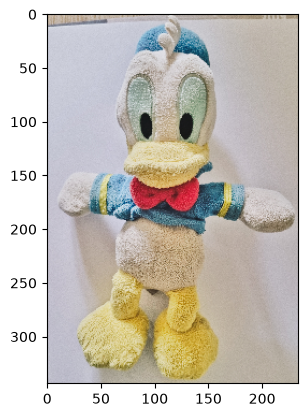

In [77]:
# Prévisualisation
preview = cv2.resize(img, None, fx=0.1, fy=0.1)
plt.imshow(preview)

In [78]:
# Rotation
#plt.imshow(np.rot90(preview, k=2))
#img = np.rot90(img, k=2)

In [80]:
# 3- Réduction de l'image à la taille du canvas (MaxPool2D)
img = img.reshape(1, *img.shape)#\

for _ in range(int(np.ceil(np.log2(max(img.shape)/SIZE)))):
    img = layers.MaxPool2D(pool_size=2)(img)
img.shape

ValueError: Input 0 with name 'None' of layer 'max_pooling2d_50' is incompatible with the layer: expected ndim=4, found ndim=5. Full shape received: (1, 1, 3437, 2335, 3)

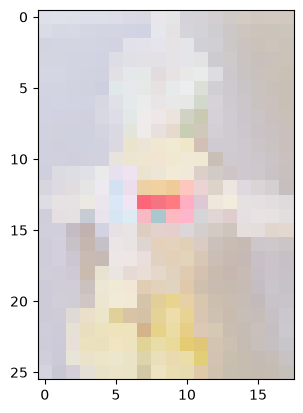

In [70]:
plt.imshow(img[-1, 0:])

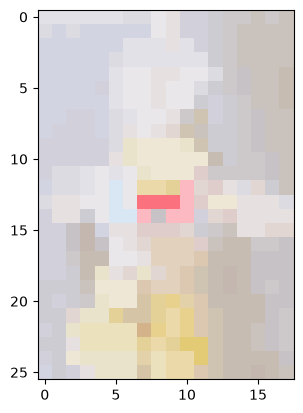

In [71]:
# 4- Réduction du nombre de couleurs (KMeans)
img = np.array(img)[-1, 0:]
pixels = img.reshape(-1, 3)

cls = KMeans(n_clusters=N_COULEURS)
cls.fit_transform(pixels)

cls_img = cls.cluster_centers_[cls.labels_]\
    .astype('int')\
    .reshape(img.shape)
plt.imshow(cls_img)

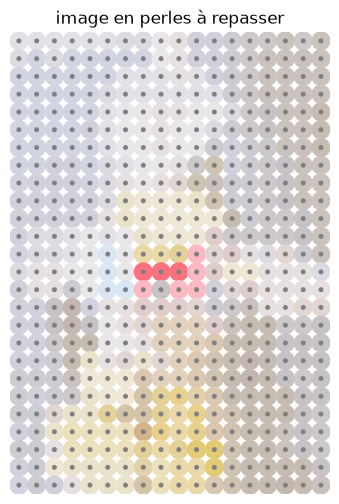

In [72]:
# 5- Visualisation de l'image en perles à repasser
h, l = cls_img.shape[0], cls_img.shape[1]

# Coordonnées de tous les pixels
y, x = np.mgrid[0:h, 0:l]
couleurs = cls_img.reshape(-1, 3)/255.0

fig, ax = plt.subplots(figsize=(6, 6))
for (yy, xx), c in zip(zip(y.ravel(), x.ravel()), couleurs):
    ax.add_patch(plt.Circle((xx, yy), 0.5, color=c))
    ax.add_patch(plt.Circle((xx, yy), 0.1, color='grey'))
ax.set_xlim(-0.5, l - 0.5); ax.set_ylim(h - 0.5, -0.5)
ax.set_aspect("equal"); ax.axis("off")
plt.title("image en perles à repasser")
plt.savefig(f'../data/out/_{os.path.basename(IMG_PATH)}')